# 04 — Reflection

This notebook synthesises what we learned from the full pipeline and is honest about where the analysis falls short.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

dc = pd.read_csv('../data/daily_counts.csv', parse_dates=['date']).set_index('date').sort_index()

## 1. What the data shows

**Finding 1 — Geographic inequality of alerts.**  
Frontline oblasts accumulate 3–5× more alarm events than western oblasts. The heatmap in `01_eda.ipynb` makes this structural pattern visible and stable across time.

**Finding 2 — Attack timing is not uniform across the day.**  
The hour-of-day plot (Kyiv time) shows a clear pattern: the majority of alarms start in the pre-dawn and morning hours. This is a learnable feature that any future model should include.

**Finding 3 — The series is non-stationary.**  
The 7-day rolling mean on the daily count shows at least two visible shifts in the overall level of activity — visible in the plot below. A model learned in one regime does not transfer cleanly to the next.

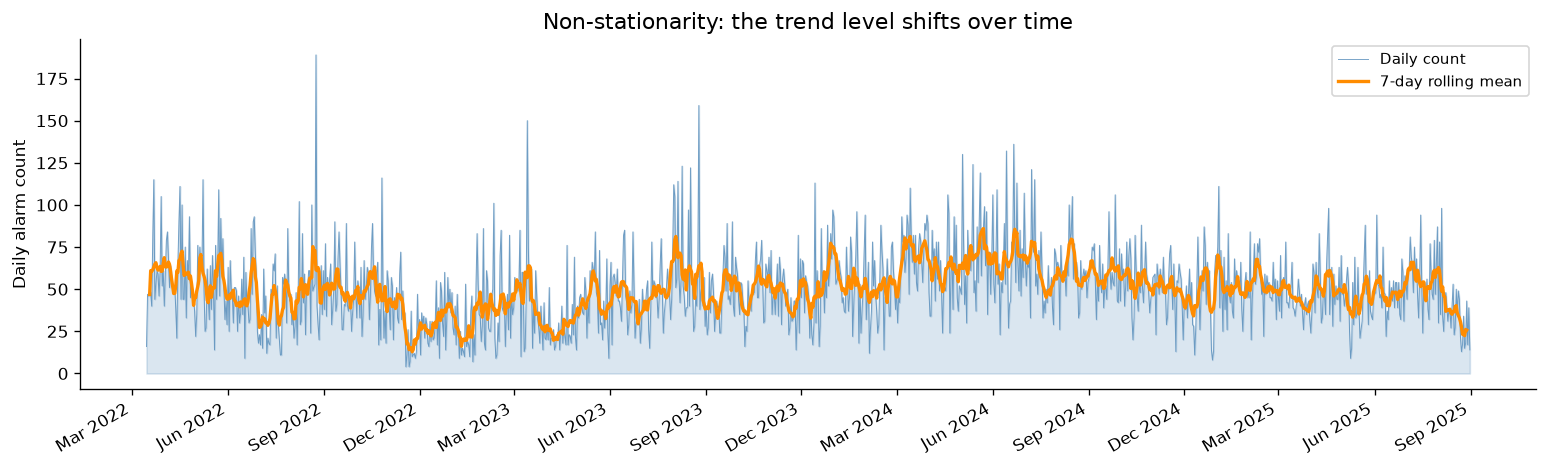

In [6]:
ANALYSIS_END = '2025-08-31'
dc_plot = dc.loc[:ANALYSIS_END]

fig, ax = plt.subplots(figsize=(13, 4))
ax.fill_between(dc_plot.index, dc_plot['n_alarms'], alpha=0.2, color='steelblue')
ax.plot(dc_plot.index, dc_plot['n_alarms'], color='steelblue', linewidth=0.6, alpha=0.7, label='Daily count')
rolling = dc_plot['n_alarms'].rolling(7, center=True).mean()
ax.plot(dc_plot.index, rolling, color='darkorange', linewidth=2, label='7-day rolling mean')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.xticks(rotation=30, ha='right')
ax.set_ylabel('Daily alarm count')
ax.set_title('Non-stationarity: the trend level shifts over time', fontsize=13)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 2. Forecast quality

Test set: **3 Jul – 31 Aug 2025** (60 days), data clipped at `ANALYSIS_END = 2025-08-31` to avoid the collection artifact that collapses counts to near-zero after that date.

| Baseline | MAE | RMSE |
|---|---|---|
| Naive persistence (t-1) | 19.70 | 24.65 |
| **7-day rolling mean** | **14.28** | **17.69** |
| Weekly seasonal naive (t-7) | 18.63 | 24.07 |

Mean daily count on the test set: **46.6 alarms/day** (std 20.5).  
Best baseline MAE = 14.28 ≈ **31% of the mean** — a large relative error.

**Why rolling mean wins.** It does not predict structure — it damps noise. By averaging the last seven days it avoids over-reacting to single-day spikes that persistence amplifies. The gain over persistence (~5 MAE units) is noise-smoothing, not signal-finding.

**The spike problem.** Residual analysis shows a systematic pattern: the model under-predicts sharply on days with mass missile or drone strikes (actual − predicted >> 0) and over-predicts in the quiet lull that follows. These peaks drive the bulk of RMSE. No autoregressive baseline can anticipate them because they are initiated by military decisions exogenous to the series.

**Honest verdict:** even on clean data the series resists prediction. The MAE of the best baseline is ~30% of the daily mean — too large for any operational use. This is a property of the phenomenon: the primary causes of today's alarms (missile inventory, weather, strategic priorities) are not in the dataset at all. A univariate model is fitting correlated noise, not a causal signal. Correctly diagnosing *why* a model fails is the useful result here, not the metric itself.

## 3. Data limitations

### 3a. Multi-level records — the silent triple-counting trap

The official dataset records alarms at three administrative levels simultaneously: oblast, raion, and hromada.  
One real alarm event can appear as 1 + N + M rows in the CSV.  
If you group by date without filtering `level == 'oblast'`, your daily count is **inflated by ~2.1×** — this passes all type checks and produces plausible-looking numbers, which is exactly why it is dangerous.

### 3b. Duration outliers

A small number of records have `finished_at` values hundreds of days after `started_at` — these are almost certainly stale entries where the end time was never updated.  
In this project we flagged and excluded them from duration analysis.  
They do not affect alarm counts (which only use `started_at`).

### 3c. Early dataset period

The dataset starts on 2022-03-15, roughly three weeks after the full-scale invasion began on February 24, 2022. The first 6–8 weeks of data may be under-reported as the national alert system was still being organised. We excluded the first ~6 weeks from model training (`start_date = 2022-05-01`).

### 3d. The timezone trap

Raw timestamps carry `+00:00` (UTC). Grouping by date in UTC places late-evening alarms (22:00–23:59 Kyiv time) on the next UTC calendar day. Over hundreds of days, this shifts roughly 8–10% of records to the wrong day.  
The fix is a single call to `.dt.tz_convert('Europe/Kyiv')` **before** any `.dt.date` groupby.

### 3e. Oblast granularity

Even at the `level='oblast'` granularity, an alarm covers an entire oblast (avg. ~26,000 km²). The dataset does not say which part of the oblast was actually under threat. Geographic sub-oblast analysis is not possible without finer data.

## 4. Why conflict events are hard to forecast

Time-series forecasting works well when the signal has **stable, repeating structure** (seasons, business cycles). Air raid alerts satisfy none of these:

1. **Non-stationarity.** Mean and variance shift with the conflict. A model trained in a low-intensity period systematically under-predicts during escalation.

2. **Exogenous drivers.** The primary cause of today's alarms — missile inventory, weather, strategic priorities — is not in this dataset at all. A univariate model is forecasting correlated noise.

3. **Rare high-impact events.** Mass missile strikes generate disproportionate forecast error. These events appear essentially unpredictable from alarm history alone.

This is a property of the phenomenon, not a failure of the analysis.  
Correctly identifying *why* a model doesn't work is valuable knowledge.

## 5. What would improve this

| Improvement | Expected impact | Difficulty |
|-------------|----------------|------------|
| Weekday + month calendar features | Low–moderate | Easy |
| Multi-horizon lag features (14d, 30d) | Low — non-stationarity limits benefit | Easy |
| Publicly available ceasefire / escalation event log | Moderate | Medium (manual curation) |
| Weather data (cloud cover limits air operations) | Low–moderate | Medium (API) |
| Raion / hromada level analysis (finer geography) | High for geographic work | Medium (data already in CSV) |

A practical immediate next step: add weekday dummies to a linear model and measure whether MAE improves on the test set.

## 6. Personal learning notes

*(Fill in after completing the project — what was surprising, what was harder than expected, what you would do differently with more time.)*

- ...
- ...
- ...